# Chapter 4 (part 4) — Regression Diagnostics: How Much Should I Trust a Stock's Beta?

Covers: Regression Diagnostics → Outliers, Influential Values, Heteroskedasticity, Non-Normality and Correlated Errors, Partial Residual Plots and Nonlinearity, on the **markets** data.

**Chapter thread, continued:** notebooks 08-10 asked what a coefficient means; here we ask whether it deserves trust. **Project question: how much should I trust a stock's beta?** Beta is the slope of a stock's daily excess return (return minus the risk-free rate) on the market's excess return (`Mkt_RF`, from Fama-French). The data: about 2,500 trading days (2016-2025) for 66 large-cap US stocks plus the three Fama-French factors. It is a time series with fat tails and turbulent stretches, which is exactly where textbook assumptions strain.

**How to work each section** (~10-15 min each): write your one-line prediction **before** running anything, do the code, then write 2-3 bullets on what matched and what didn't. Ask for a hint if you get stuck. The exam for this notebook lives in `reviews/R01_regression-diagnostics.ipynb`.

In [2]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson
from statsmodels.nonparametric.smoothers_lowess import lowess

pd.set_option("display.max_columns", None)

from mlstats.data import load_returns, load_factors

excess = load_returns(excess=True)   # daily simple return minus RF, one column per ticker
factors = load_factors()             # Mkt_RF, SMB, HML, RF (decimals)


def stock_frame(ticker):
    """One stock's daily excess return as `y`, next to the three factors."""
    return pd.concat([excess[ticker].rename("y"), factors[["Mkt_RF", "SMB", "HML"]]], axis=1)


low = stock_frame("LOW")   # sections 1-3
spg = stock_frame("SPG")   # section 4
low.shape, low.index.min().date(), low.index.max().date()

((2513, 4), datetime.date(2016, 1, 5), datetime.date(2025, 12, 31))

In [3]:
low.head()

,y,Mkt_RF,SMB,HML
2016-01-05,0.002125,0.0013,-0.0018,0.0000
2016-01-06,-0.019883,-0.0134,-0.0013,0.0001
2016-01-07,-0.025291,-0.0244,-0.0030,0.0008
2016-01-08,-0.016512,-0.0111,-0.0049,-0.0003
2016-01-11,0.025395,-0.0006,-0.0064,0.0040


## 1. Outliers and Influential Values

Covers: *Outliers* and *Influential Values* (book: Regression Diagnostics). A big residual and a big influence are different things. Numeric picture: the fitted line is a seesaw balanced on the cloud of points. About 2,500 days sit within a couple of percent of a market move of zero; moving one of them by 5 points barely tilts the line. One day with the market at −6% sits far out on the plank, so moving *it* by 5 points tilts the whole line. Influence is roughly **leverage** (how far out on the plank, a function of x only) × **how surprising the residual is**. Cook's distance combines the two; the studentized residual measures only the surprise.

**Predict first:** if you drop the single day with the largest Cook's distance, will LOW's beta move by less than 0.01, by about 0.05, or by more than 0.15? And will that day be a company earnings date or a market-wide crash day?

**Question 1.** (a) Fit LOW's excess return on `Mkt_RF`. (b) Build a DataFrame `diag` (indexed by date) with Cook's distance, leverage, and the externally studentized residual for every day; the cell after it prints the top days and plots them. (c) Refit dropping the 1, 3, and 10 most influential days (by Cook's distance), and also dropping every day from 2020-02-15 to 2020-04-30. Collect the betas in `betas`.

*Tools for this question:*
- `smf.ols("y ~ Mkt_RF", df).fit()`; `res.get_influence()` returns an `OLSInfluence` object.
- On it: `.cooks_distance` is a **tuple** `(distances, p_values)`, take `[0]`; `.hat_matrix_diag` is leverage; `.resid_studentized_external` is the studentized residual. All three are plain numpy arrays, so pass `index=df.index` when you build the DataFrame.
- `diag["cooks"].nlargest(k).index` gives the k dates; `df.drop(index=dates)` removes them.

_Prediction (one line, before running anything):_
* I dont have much experience in financial market analysis. However, I believe that removing removing one point out of 2513 would move the beta by 0.05 since it seems like 0.15 would be too much for one point to drag a coefficient that another 2512 contribute towards. I believe that point could be an earnings date since an outlier point could mean an extremely poor or good earnings report.

In [4]:
model = smf.ols("y ~ Mkt_RF", data = low).fit()  # OLS of LOW's excess return y on Mkt_RF
model.params

Intercept    0.000079
Mkt_RF       0.998771
dtype: float64

In [5]:
infl = model.get_influence()  # the influence object from the fitted model

data = {"cooks": infl.cooks_distance[0], "leverage" : infl.hat_matrix_diag, "stud_resid" : infl.resid_studentized_external}

diag = pd.DataFrame(data, index = low.index)  # DataFrame indexed by date with columns: cooks, leverage, stud_resid

             cooks  leverage  stud_resid       y  Mkt_RF
2020-03-16  1.9518    0.0425     -9.5459 -0.2478 -0.1201
2020-03-24  0.1494    0.0253      3.3975  0.1400  0.0934
2025-04-09  0.1314    0.0270     -3.0811  0.0542  0.0965
2025-04-04  0.1094    0.0107      4.5117  0.0033 -0.0592
2020-03-18  0.1006    0.0095     -4.5958 -0.1190 -0.0556
2020-03-10  0.0562    0.0067      4.0793  0.1039  0.0474
2020-03-17  0.0482    0.0102     -3.0610  0.0164  0.0588
2020-03-09  0.0372    0.0182     -2.0056 -0.1054 -0.0779
rule-of-thumb cutoff 4/n = 0.0016 | days above it: 121 of 2513


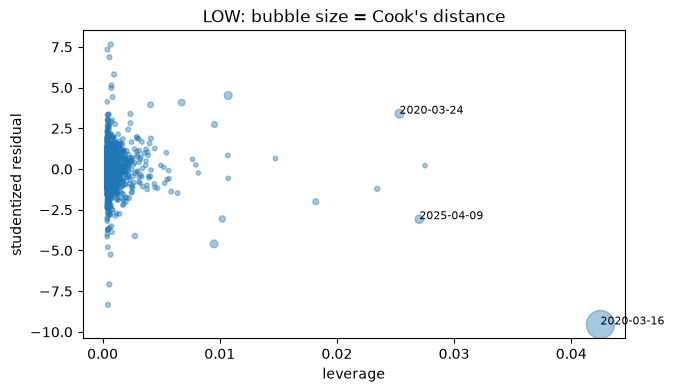

In [6]:
# pre-filled: consumes your `diag`
top = diag.join(low[["y", "Mkt_RF"]]).sort_values("cooks", ascending=False).head(8)
print(top.round(4))
print("rule-of-thumb cutoff 4/n =", round(4 / len(low), 4), "| days above it:", int((diag["cooks"] > 4 / len(low)).sum()), "of", len(low))

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(diag["leverage"], diag["stud_resid"], s=10 + 400 * diag["cooks"] / diag["cooks"].max(), alpha=0.4)
for d in top.index[:3]:
    ax.annotate(str(d.date()), (diag.loc[d, "leverage"], diag.loc[d, "stud_resid"]), fontsize=8)
ax.set_xlabel("leverage"); ax.set_ylabel("studentized residual"); ax.set_title("LOW: bubble size = Cook's distance")
plt.show()

In [7]:
betas = {}  # label -> LOW beta, e.g. betas['all days'], betas['drop top 1'], ..., betas['drop Feb15-Apr30 2020']

In [8]:
# dropping top 1,3, and 10 most influential point
for i in [1,3,10,"Date Range Drop"]:
    if isinstance(i,int):
        drop_top_x_df = low.drop(index = diag["cooks"].nlargest(i).index)

        # refit 
        m_i = smf.ols("y ~ Mkt_RF", data = drop_top_x_df).fit()

        # append beta
        betas[f"Top {i} removed beta"] = m_i.params["Mkt_RF"]

    else:
        dates_to_drop = low.loc["2020-02-15":"2020-04-30"]
        drop_date_range_df = low.drop(dates_to_drop.index)

        # refit
        covid_model = smf.ols("y ~ Mkt_RF", data = drop_date_range_df).fit()

        # append beta
        betas[f"Date range removed beta"] = covid_model.params["Mkt_RF"]





In [9]:
pd.Series(betas).round(4)  # pre-filled

Top 1 removed beta         0.9522
Top 3 removed beta         0.9487
Top 10 removed beta        0.9365
Date range removed beta    0.8933
dtype: float64

_What matched, what surprised you, and why (2-3 bullets):_
* Seems like removing the most influential point with the largest cooks distance really made the beta go down by roughly 0.05 which was what I predicted.
* What suprised me was how dropping all the points in the date range contributed to the largest drop in beta. I guess this make sense since you're dropping a solid chunk of data that would have contributed towards the coefficient.
* I was wrong to say that one point wouldn't move the coefficient that much becuase it did. Influence isn't just how far the point is compared to the other points. It is essentially the leverage of a point multplied by its residual and since the point is an outlier the error is likely large making the product large. So not due to sample size.
* Also I predicted that the days with the biggest beta movement would be an earnings report but clearly it was a major market crash as the top covid day removed took the original beta from 0.988 to 0.893.

## 2. Heteroskedasticity

Covers: *Heteroskedasticity, Non-Normality and Correlated Errors* (book). Classical OLS standard errors assume every day's residual has the same spread. Numeric picture of what breaks: the slope's uncertainty is driven by `x² · e²` summed over days. A typical day (market move 1%, residual 1%) contributes 1e-4 × 1e-4 = 1e-8. A wild day (market −6%, residual −5%) contributes 0.0036 × 0.0025 = 9e-6, about 900 typical days' worth. If big residuals live on big-|x| days, the classical SE (one averaged σ² for everybody) is wrong, while **HC3** robust SEs (which use each day's own residual and leverage) are not.

Careful what Breusch-Pagan tests: as called here it checks whether the residual *variance moves linearly with the regressor* `Mkt_RF`. It is blind to variance that rises on big days in *both* directions (add `Mkt_RF**2` to its auxiliary regression and it becomes White's test), and it says nothing about variance drifting over *time*. HC3 stays sensitive to the `x² · e²` pattern either way. Clustering in time is section 3.

**Predict first:** will HC3's SE for beta be about the same as the classical one, about 1.5× bigger, or more than 2× bigger? Does the beta estimate itself change? And if you remove the single most influential day from section 1, will Breusch-Pagan still reject?

**Question 2.** (a) Run Breusch-Pagan on your section-1 `model`. (b) Refit with HC3 standard errors as `model_hc3`; the pre-filled table compares them. (c) Repeat (a) and (b) on `low_wo_top` (LOW without its most influential day, built for you), storing `bp_wo` and `model_hc3_wo`.

*Tools for this question:*
- `het_breuschpagan(resid, exog_het, robust=True)` returns **4 values** `(lm_stat, lm_pvalue, f_stat, f_pvalue)`. `exog_het` must include the constant column: use `model.model.exog`. The default `robust=True` is the Koenker version, which suits fat tails.
- HC3: `smf.ols(...).fit(cov_type="HC3")`; compare `.bse["Mkt_RF"]`. The coefficients are identical by construction.
- `het_white(resid, exog)` also returns 4 values `(lm_stat, lm_pvalue, f_stat, f_pvalue)`; the last pre-filled cell calls it for you. In your reflection, compare the BP p-value, the SE ratio, and the White p-value, with and without the top day.

_Prediction (one line, before running anything):_
* I would imagine that the HC3's SE for beta would be about 1.5x bigger?
* HC3 doesn't change the coefficients so beta estimate would stay the same.
* You mentioned that Breusch-Pagan is bling to rises on big days so I believe that the consense the test reaches would not change

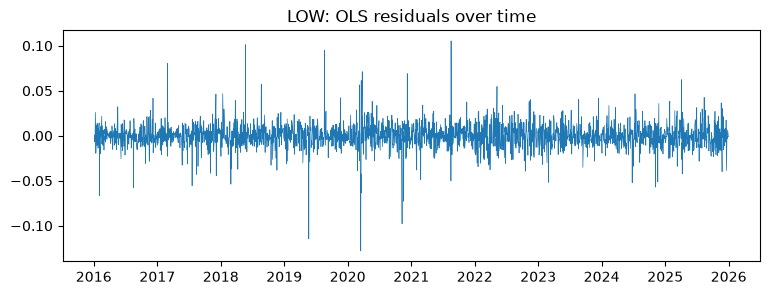

In [10]:
# pre-filled: residuals over time (consumes your `model`)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(model.resid.index, model.resid.values, lw=0.5)
ax.set_title("LOW: OLS residuals over time"); plt.show()

In [11]:
bp = het_breuschpagan(resid = model.resid, exog_het = model.model.exog, robust=True) # Breusch-Pagan on `model` (the 4-tuple)

In [12]:
model_hc3 = smf.ols("y ~ Mkt_RF", data = low).fit(cov_type="HC3")   # same regression, HC3 standard errors

In [13]:
# pre-filled: consumes `model` and `model_hc3`
print(pd.DataFrame({"coef": model.params, "classical SE": model.bse, "HC3 SE": model_hc3.bse,
                    "SE ratio": model_hc3.bse / model.bse}).round(4))
print("Breusch-Pagan p-value:", bp[1])

             coef  classical SE  HC3 SE  SE ratio
Intercept  0.0001        0.0003  0.0003    1.0244
Mkt_RF     0.9988        0.0237  0.0584    2.4645
Breusch-Pagan p-value: 2.1486908746449355e-06


In [14]:
low_wo_top = low.drop(index=diag["cooks"].idxmax())   # pre-filled
low_wo_top_model = smf.ols("y ~ Mkt_RF", data = low_wo_top).fit()
bp_wo = het_breuschpagan(resid = low_wo_top_model.resid, exog_het = low_wo_top_model.model.exog, robust=True)        # Breusch-Pagan on the regression without that day
model_hc3_wo = smf.ols("y ~ Mkt_RF", data = low_wo_top).fit(cov_type="HC3")  # HC3 fit without that day

In [15]:
# pre-filled
print("BP p-value without the top day:", bp_wo[1])
m_wo = smf.ols("y ~ Mkt_RF", low_wo_top).fit()
print("SE ratio (HC3 / classical) without the top day:", round(model_hc3_wo.bse["Mkt_RF"] / m_wo.bse["Mkt_RF"], 2))
print("White test p-value (with Mkt_RF squared in the auxiliary regression): all days",
      het_white(model.resid, model.model.exog)[1], "| without the top day", het_white(m_wo.resid, m_wo.model.exog)[1])

BP p-value without the top day: 0.9943391780170496
SE ratio (HC3 / classical) without the top day: 1.55
White test p-value (with Mkt_RF squared in the auxiliary regression): all days 7.624814996432955e-60 | without the top day 1.3058899966301112e-07


_What matched, what surprised you, and why (2-3 bullets):_
* What I learned: traditional standard errors in OLS pools errors together and average them which doesnt reflect the errors caused by wild/outlier data points. HC3 computes standard error in a way that uses each day's own residuals to better reflect uncetainty in the coefficient.
* My prediction that beta wouldn't move between classical and HC3 was correct, and what changed was the standard error. I predicted HC3's SE would be about 1.5x the classical one, but the actual ratio was 2.46, so I underestimated how much the classical SE understated the uncertainty.
* The Breusch-Pagan tests whether a residual is linked with the regressors. The null states "the spread of the residual doesn't change with Mkt_RF". It rejected when all days were in the regression, indicating that the spread likely changes with Mkt_RF. I predicted its verdict wouldn't change, but I was wrong: when we removed the top day the p-value flipped to not significant (0.99). That day is the one with the biggest Cook's distance, 2020-03-16 (the Covid crash), so one high-leverage day was creating the linear link between spread and Mkt_RF.
* An SE ratio of 1 would mean constant variance, and removing the top day didn't bring it to 1 (it was 1.55). The White test, which also lets the spread depend on Mkt_RF squared, still rejects without that day (p about 1e-7) even though Breusch-Pagan no longer does. So the variance still rises on big market days in both directions, which the linear Breusch-Pagan test can't see, and HC3 is still needed.

## 3. Correlated Errors

Covers: *Correlated Errors* (book; it matters far more here than the book lets on). Two different failures live here.

**(i) Uncorrelated is not independent.** Numeric picture: residuals of +1%, −1%, +1%, −1% on calm days and +5%, −6%, +4%, −5% on turbulent days. Their *signs* are random, so the average product of neighbors is near zero and the residuals look uncorrelated. Yet the *sizes* clearly cluster (calm next to calm, wild next to wild), so the *squares* are correlated.

**(ii) Overlapping returns.** The 20-day return ending today and the one ending yesterday share 19 of their 20 daily returns, so their regression errors are almost the same number. Rule of thumb: Durbin-Watson ≈ 2(1 − ρ), where ρ is the correlation between neighboring residuals. With ρ = 0.5 that is DW ≈ 1; with ρ = 0.9, DW ≈ 0.2. The point estimates are still fine, but the *standard errors* are far too small. Newey-West (HAC) standard errors repair this, with `maxlags` set to the window length minus 1.

**Predict first:** the lag-1 autocorrelation of LOW's daily residuals: near 0, near +0.3, or near −0.3? Is the lag-1 autocorrelation of the *squared* residuals bigger or smaller in size? And will the overlapping 20-day regression's Durbin-Watson be near 2, near 1, or near 0.2?

**Question 3.** (a) Compute the autocorrelation of `model.resid` and of `model.resid ** 2` at lags 1-5 (`acf_e`, `acf_e2`). (b) Fit the overlapping 20-day regression on the pre-built frame `w` as `model20` and compute its Durbin-Watson as `dw20`. (c) Refit `model20` with HAC standard errors (`maxlags=19`) as `model20_hac`. The pre-filled cell compares it with non-overlapping windows, started at each of the 20 possible offsets. Notice that the 20-day beta is not the daily beta; say why in your reflection.

*Tools for this question:*
- `pd.Series.autocorr(lag=k)` for each k. Return a list of **5 values for lags 1-5** (no lag 0), since the pre-filled table assumes it. (`acorr_ljungbox(x, lags=[10])` returns a DataFrame with a joint p-value if you want a formal test.)
- `durbin_watson(res.resid)` takes the residual series.
- HAC: `.fit(cov_type="HAC", cov_kwds={"maxlags": 19})`.

_Prediction (one line, before running anything):_
* I believe that the correlation between the current days residuals and the previous days residuals will be near 0.
* The squared residuals will like show a stronger relationship so I believe they will be bigger in size.
* I believe that with each observation sharing 19/20 data points, the correlation between neighboring residuals will be quite high resulting in a durbin watson of around 0.2.

In [16]:

acf_e = [model.resid.autocorr(lag=k) for k in range(1, 6)]   # lags 1-5 autocorrelations of the daily residuals

squared_resid = (model.resid**2)
acf_e2 = [squared_resid.autocorr(lag=k) for k in range(1, 6)]  # lags 1-5 autocorrelations of the squared daily residuals
pd.DataFrame({"resid": np.asarray(acf_e), "resid^2": np.asarray(acf_e2)}, index=range(1, 6)).round(3)

,resid,resid^2
1,-0.003,0.088
2,0.014,0.063
3,-0.024,0.067
4,-0.006,0.071
5,-0.042,0.050


In [17]:
# pre-filled: 20-day windows built from a rolling SUM of daily excess returns
# (an approximation to compounding that is fine at this scale). Consecutive rows overlap by 19 days.
w = low[["y", "Mkt_RF"]].rolling(20).sum().dropna()
w.shape

(2494, 2)

In [18]:
model20 = smf.ols("y ~ Mkt_RF", data = w).fit()  # OLS of the 20-day y on the 20-day Mkt_RF
dw20 = durbin_watson(model20.resid)     # Durbin-Watson of its residuals

In [19]:
model20_hac = smf.ols("y ~ Mkt_RF", data = w).fit(cov_type="HAC", cov_kwds={"maxlags": 19})  # same regression with HAC standard errors, maxlags=19

In [20]:
# pre-filled: consumes model20, dw20, model20_hac
print("Durbin-Watson, 20-day overlapping:", round(dw20, 3))
nonover = smf.ols("y ~ Mkt_RF", w.iloc[::20]).fit()   # every 20th row: no shared days
print(pd.DataFrame({"beta": [model20.params["Mkt_RF"], model20.params["Mkt_RF"], nonover.params["Mkt_RF"]],
                    "SE": [model20.bse["Mkt_RF"], model20_hac.bse["Mkt_RF"], nonover.bse["Mkt_RF"]],
                    "n": [len(w), len(w), len(w.iloc[::20])]},
                   index=["overlapping, classical SE", "overlapping, HAC SE", "non-overlapping (offset 0)"]).round(4))

# the same non-overlapping regression from each of the 20 possible starting offsets
offsets = pd.Series({k: smf.ols("y ~ Mkt_RF", w.iloc[k::20]).fit().params["Mkt_RF"] for k in range(20)})
print("beta across the 20 offsets: mean", round(offsets.mean(), 3), "| std", round(offsets.std(), 3),
      "| min/max", round(offsets.min(), 2), round(offsets.max(), 2))
print("daily beta from section 1:", round(model.params["Mkt_RF"], 3))

Durbin-Watson, 20-day overlapping: 0.119
                              beta      SE     n
overlapping, classical SE   1.1958  0.0251  2494
overlapping, HAC SE         1.1958  0.0928  2494
non-overlapping (offset 0)  1.4005  0.1101   125
beta across the 20 offsets: mean 1.195 | std 0.131 | min/max 0.93 1.4
daily beta from section 1: 0.999


_What matched, what surprised you, and why (2-3 bullets):_\
* My prediction that the 20 day rolling returns would produce a low Durbin-Watson was correct. I predicted around 0.2 and got 0.119, even lower, which indicates severe positive autocorrelation. That makes sense since 19 of every 20 values carry over from one day to the next.
* In terms of squared residual autocorrelation vs regular, there was a stronger relationship for squared residuals (lag 1: 0.088 vs -0.003 for the regular residuals). The signs make the regular residuals unpredictable, so squaring removes that issue and lets you see how big misses follow big misses.
* My original prediction that the current day residual vs. previous day residual correlation would be near 0 was correct. However, it doesn't rule out the residuals being dependent. We can see that with the 20 day overlapping results, where data points with overlapping values have strong autocorrelation. This makes the standard error overly optimistic: the classical SE was 0.0251 while the HAC SE was 0.0928, about 3.7 times larger.
* One of the assumptions of linear regression is that errors are independent and the 20 day overlap violates this. 
* The 20 day beta (about 1.20) is not the same as the daily beta (0.999). Across the 20 possible starting offsets, the non-overlapping 20 day betas range from 0.93 to 1.40 with a standard deviation of 0.131, which is similar in size to the HAC SE (0.093). So a single 20 day beta is a noisy estimate, and the gap between 1.20 and 0.999 is only about two HAC standard errors. Beta can depend on the return horizon, but I haven't tested why.

## 4. Partial Residual Plot and Nonlinearity

Covers: *Partial Residual Plots and Nonlinearity* (book). A partial residual isolates one predictor's contribution after the others have done their work: `partial residual for x = residual + b_x · x`. Numeric picture: if b_Mkt = 1.0, a day with Mkt_RF = −4% and a residual of +1% has partial residual −4% + 1% = −3%. Plot that against Mkt_RF for every day: if the true relationship is a straight line of slope b_Mkt, the cloud follows the line; if it bends, a smooth curve through the cloud (lowess) leaves the line.

The model is the Fama-French three-factor regression for SPG (Simon Property): excess return on `Mkt_RF`, `SMB`, `HML`. The question is whether its market slope is the same on up days and down days: "does beta go up when the market falls?" This sets up notebook 12 (splines).

**Predict first:** will SPG's market slope on down days be steeper, flatter, or about equal to its up-day slope? Will the "extra down-market slope" coefficient come out positive or negative? Will it survive if you refit without Feb 15 - Apr 30, 2020?

**Question 4.** (a) Fit `model3` (the three-factor regression on `spg`) and compute the partial residuals for `Mkt_RF` by hand as `pr`; the plot is pre-filled. (b) Add a down-market term, `min(Mkt_RF, 0)`, to the formula and refit as `model_hinge`. (c) Refit the same hinge model on `spg_calm` (the Covid window removed, built for you) as `model_hinge_calm`.

*Tools for this question:*
- The hinge column: `I(np.minimum(Mkt_RF, 0))` inside the formula. The slope on up days is `b_Mkt`; the slope on **down days is `b_Mkt + b_hinge`**, so the hinge coefficient is the *extra* down-day slope.
- `pr` should be a Series aligned with `spg.index`: use `model3.resid` and `model3.params["Mkt_RF"]`.
- Library check, once you have computed `pr` by hand: `sm.graphics.plot_ccpr(model3, "Mkt_RF")` draws the same plot.

_Prediction (one line, before running anything):_
* I believe that SPG's market slope on downs days will be equal to its up day slope. I am trying to reconnect it to our work in auto correlation where since the signs basically cancelled out the negative and positive days, it showed a deceivingly low correlation.

* I think the extra down market slope will be negative and if we drop the COVID period it may not survive.

In [27]:
model3 = smf.ols("y ~ Mkt_RF + SMB + HML", data = spg).fit() # OLS of SPG excess return on Mkt_RF + SMB + HML

residuals = model3.resid
mkt_rf_coef = model3.params["Mkt_RF"]
pr = residuals + (mkt_rf_coef * spg["Mkt_RF"])
pr

2016-01-05    0.020636
2016-01-06   -0.009023
2016-01-07   -0.022079
2016-01-08   -0.033973
2016-01-11    0.029188
                ...   
2025-12-24    0.003808
2025-12-26    0.003175
2025-12-29    0.000437
2025-12-30   -0.005353
2025-12-31   -0.010390
Length: 2513, dtype: float64

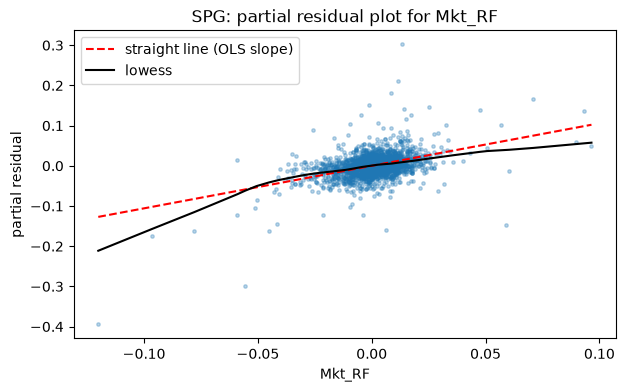

In [28]:
# pre-filled: consumes `pr` and `model3`
smooth = lowess(pr, spg["Mkt_RF"], frac=0.4)
xs = np.linspace(spg["Mkt_RF"].min(), spg["Mkt_RF"].max(), 50)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(spg["Mkt_RF"], pr, s=6, alpha=0.3)
ax.plot(xs, model3.params["Mkt_RF"] * xs, "r--", label="straight line (OLS slope)")
ax.plot(smooth[:, 0], smooth[:, 1], "k-", label="lowess")
ax.set_xlabel("Mkt_RF"); ax.set_ylabel("partial residual"); ax.legend(); ax.set_title("SPG: partial residual plot for Mkt_RF")
plt.show()

In [32]:
model_hinge =  smf.ols("y ~ Mkt_RF + SMB + HML + I(np.minimum(Mkt_RF, 0))", data = spg).fit() # three-factor model plus the down-market term

In [33]:
spg_calm = spg[(spg.index < "2020-02-15") | (spg.index > "2020-04-30")]   # pre-filled
model_hinge_calm = smf.ols("y ~ Mkt_RF + SMB + HML + I(np.minimum(Mkt_RF, 0))", data = spg_calm).fit()  # the same hinge model on the calm sample

In [34]:
# pre-filled: consumes both hinge models
hinge = lambda m: [p for p in m.params.index if "minimum" in p][0]
print(pd.DataFrame({"extra down-day slope": [model_hinge.params[hinge(model_hinge)], model_hinge_calm.params[hinge(model_hinge_calm)]],
                    "t": [model_hinge.tvalues[hinge(model_hinge)], model_hinge_calm.tvalues[hinge(model_hinge_calm)]],
                    "up-day slope (Mkt_RF)": [model_hinge.params["Mkt_RF"], model_hinge_calm.params["Mkt_RF"]]},
                   index=["all days", "Covid window removed"]).round(3))

                      extra down-day slope      t  up-day slope (Mkt_RF)
all days                             0.463  5.907                  0.814
Covid window removed                 0.054  0.647                  0.950


_What matched, what surprised you, and why (2-3 bullets):_

* Originally I predicted the down-day slope would equal the up-day slope, and that was incorrect. The extra down-day slope is +0.463 (t = 5.9), so SPG's slope is about 0.814 + 0.463 = 1.28 on down days versus 0.814 on up days. The slope isn't the return itself but how much the stock moves with the market, so on market-down days SPG fell by an extra amount. I also predicted the extra slope would be negative, but it is positive: since the market's move is negative on those days, a positive coefficient means an extra drop, not a cushion.
* After removing Feb 15 - Apr 30 2020 the extra slope falls to 0.054 (t = 0.65), which is indistinguishable from 0, so my prediction that it wouldn't survive was correct. The relationship with the market doesn't disappear (the down-day slope is still about 1.0, the same as up days); what disappears is the extra amount. So the kink came from March 2020, not from SPG behaving differently in down markets in general.
* In the partial residual plot, the lowess curve follows the straight line closely through most of the range and only drops below it in the far left tail (market moves around -10%), which is where the Covid days are. That matches the hinge result: the bend lives in a few extreme days.

**Where this leaves the project question:** write one sentence on how much you would trust LOW's daily beta, and which of the four problems (influence, heteroskedasticity, dependence, nonlinearity) mattered most for it.

I believe major events/days can act as outliers and create unstable coefficients, so I am not fully confident in LOW's daily beta. Influence mattered most: one day (2020-03-16) has a very high Cook's distance (leverage times a large residual) and moved beta from 0.9988 to 0.9522. Heteroskedasticity and overlapping returns also made the classical standard errors too small, by about 2.5x (HC3) and 3.7x (HAC on 20-day returns).